In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import itertools
import time
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("File name:", file_name)

Saving frequent_itemsets.csv to frequent_itemsets (1).csv
Dataset uploaded successfully!
File name: frequent_itemsets (1).csv


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 10 Records:")
display(df.head(10))

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (256, 2)

Column Names:
['support', 'itemsets']

First 10 Records:


,support,itemsets
0,0.0568,frozenset({'Air Freshener'})
1,0.0608,frozenset({'Apple 1kg'})
2,0.0600,frozenset({'Banana 1kg'})
3,0.0578,frozenset({'Banana Chips 150g'})
4,0.0604,frozenset({'Bar Soap 125g'})
5,0.1982,frozenset({'Basmati Rice 5kg'})
6,0.0668,frozenset({'Besan 1kg'})
7,0.0588,frozenset({'Brown Bread 400g'})
8,0.0626,frozenset({'Butter 100g'})
9,0.0670,frozenset({'Buttermilk 1L'})



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   support   256 non-null    float64
 1   itemsets  256 non-null    object 
dtypes: float64(1), object(1)
memory usage: 4.1+ KB

Missing Values:
support     0
itemsets    0
dtype: int64

Statistical Summary:


,support
count,256.000000
mean,0.051328
std,0.043372
min,0.020200
25%,0.029350
50%,0.036800
75%,0.056800
max,0.254600


In [4]:
df = df.dropna(subset=['support', 'itemsets'])
df['support'] = pd.to_numeric(df['support'], errors='coerce')

df = df.dropna(subset=['support'])
# Extract product names from itemsets
def extract_items(value):
    return frozenset(re.findall(r"""['"]([^'"]+)['"]""", str(value)))
df['itemsets'] = df['itemsets'].apply(extract_items)

# Remove empty itemsets
df = df[df['itemsets'].apply(len) > 0]

# Remove duplicate itemsets
df = df.drop_duplicates(subset=['itemsets'])

In [5]:
df['itemset_size'] = df['itemsets'].apply(len)
print("Number of itemsets by size:")
print(df['itemset_size'].value_counts().sort_index())

print("\nTop 10 Frequent Itemsets:")

top_itemsets = df.sort_values(
    by='support', ascending=False
).head(10).copy()

top_itemsets['Products'] = top_itemsets['itemsets'].apply(
    lambda x: ', '.join(sorted(x))
)

top_itemsets['Support (%)'] = top_itemsets['support'] * 100

display(top_itemsets[['Products', 'Support (%)']])

Number of itemsets by size:
itemset_size
1    60
2    78
3    86
4    30
5     2
Name: count, dtype: int64

Top 10 Frequent Itemsets:


,Products,Support (%)
59,White Bread 400g,25.46
55,Toned Milk 1L,25.40
136,"Toned Milk 1L, White Bread 400g",23.84
44,Potato Chips 90g,21.84
14,Cola 750ml,21.64
56,Toor Dal 1kg,20.68
15,Cooking Oil 1L,19.96
5,Basmati Rice 5kg,19.82
89,"Cola 750ml, Potato Chips 90g",19.74
13,Choco Cookies 150g,17.76


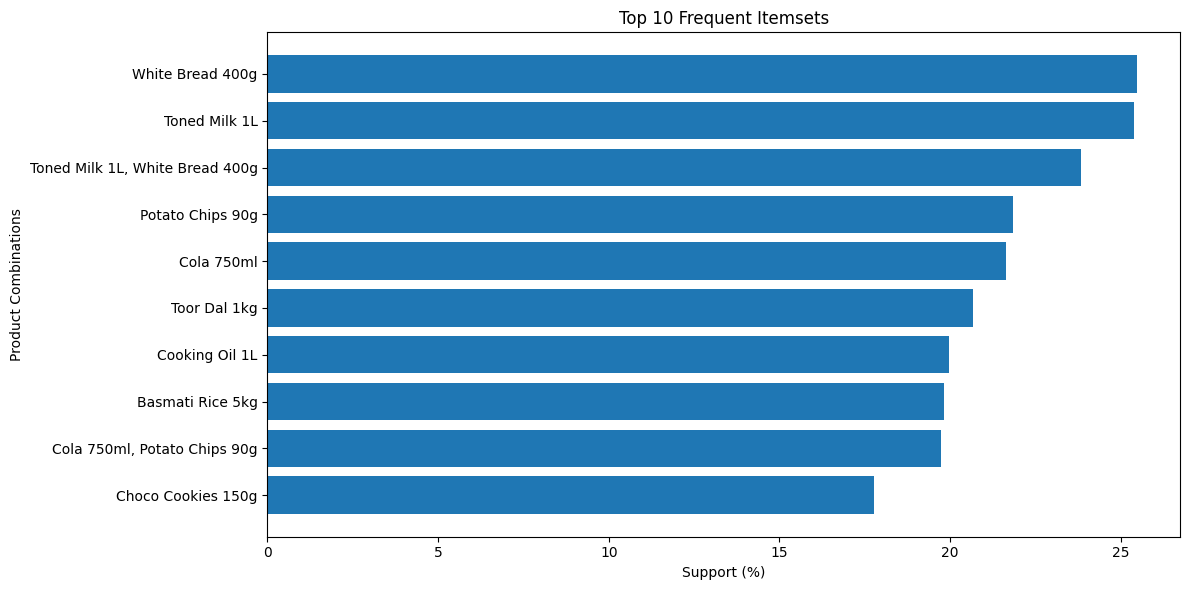

In [6]:
# Step 6: Visualisation of Frequent Itemsets

plt.figure(figsize=(12, 6))

plot_data = top_itemsets.sort_values('support')

plt.barh(
    plot_data['Products'],
    plot_data['support'] * 100
)

plt.xlabel("Support (%)")
plt.ylabel("Product Combinations")
plt.title("Top 10 Frequent Itemsets")

plt.tight_layout()
plt.show()

In [7]:
# Step 7: Generate Association Rules

support_dict = dict(
    zip(df['itemsets'], df['support'])
)

rules_list = []

for itemset, support_union in support_dict.items():

    if len(itemset) < 2:
        continue

    items = list(itemset)

    for r in range(1, len(items)):

        for antecedent_tuple in itertools.combinations(items, r):

            antecedent = frozenset(antecedent_tuple)
            consequent = itemset - antecedent

            if antecedent in support_dict and consequent in support_dict:

                support_a = support_dict[antecedent]
                support_b = support_dict[consequent]

                confidence = support_union / support_a

                lift = confidence / support_b

                rules_list.append({
                    'Antecedents': ', '.join(sorted(antecedent)),
                    'Consequents': ', '.join(sorted(consequent)),
                    'Support': support_union,
                    'Confidence': confidence,
                    'Lift': lift
                })

rules = pd.DataFrame(rules_list)

rules = rules.drop_duplicates()

print("Association rules generated:", len(rules))

display(rules.head(10))

Association rules generated: 1152


,Antecedents,Consequents,Support,Confidence,Lift
0,Basmati Rice 5kg,Choco Cookies 150g,0.0342,0.172553,0.971582
1,Choco Cookies 150g,Basmati Rice 5kg,0.0342,0.192568,0.971582
2,Basmati Rice 5kg,Cola 750ml,0.0436,0.219980,1.016543
3,Cola 750ml,Basmati Rice 5kg,0.0436,0.201479,1.016543
4,Basmati Rice 5kg,Cooking Oil 1L,0.1462,0.737639,3.695585
5,Cooking Oil 1L,Basmati Rice 5kg,0.1462,0.732465,3.695585
6,Face Wash 100ml,Basmati Rice 5kg,0.0306,0.194904,0.983373
7,Basmati Rice 5kg,Face Wash 100ml,0.0306,0.154390,0.983373
8,Basmati Rice 5kg,Ghee 500ml,0.0366,0.184662,1.082426
9,Ghee 500ml,Basmati Rice 5kg,0.0366,0.214537,1.082426


In [8]:
# Step 8: Filter Actionable Rules

actionable_rules = rules[
    (rules['Support'] > 0.05) &
    (rules['Lift'] > 2)
].copy()

actionable_rules = actionable_rules.sort_values(
    by='Lift', ascending=False
)

print("Number of Actionable Rules:", len(actionable_rules))

display(actionable_rules.head(20))


Number of Actionable Rules: 42


,Antecedents,Consequents,Support,Confidence,Lift
104,Poha 500g,Ghee 500ml,0.1468,0.864547,5.067682
105,Ghee 500ml,Poha 500g,0.1468,0.860492,5.067682
86,Face Wash 100ml,Hand Sanitizer 200ml,0.1318,0.839490,5.051086
87,Hand Sanitizer 200ml,Face Wash 100ml,0.1318,0.793020,5.051086
34,Instant Coffee 100g,Choco Cookies 150g,0.1520,0.858757,4.835344
35,Choco Cookies 150g,Instant Coffee 100g,0.1520,0.855856,4.835344
59,Potato Chips 90g,Cola 750ml,0.1974,0.903846,4.176738
58,Cola 750ml,Potato Chips 90g,0.1974,0.912200,4.176738
460,"Cola 750ml, Toned Milk 1L",Potato Chips 90g,0.0518,0.908772,4.161044
457,Potato Chips 90g,"Cola 750ml, Toned Milk 1L",0.0518,0.237179,4.161044


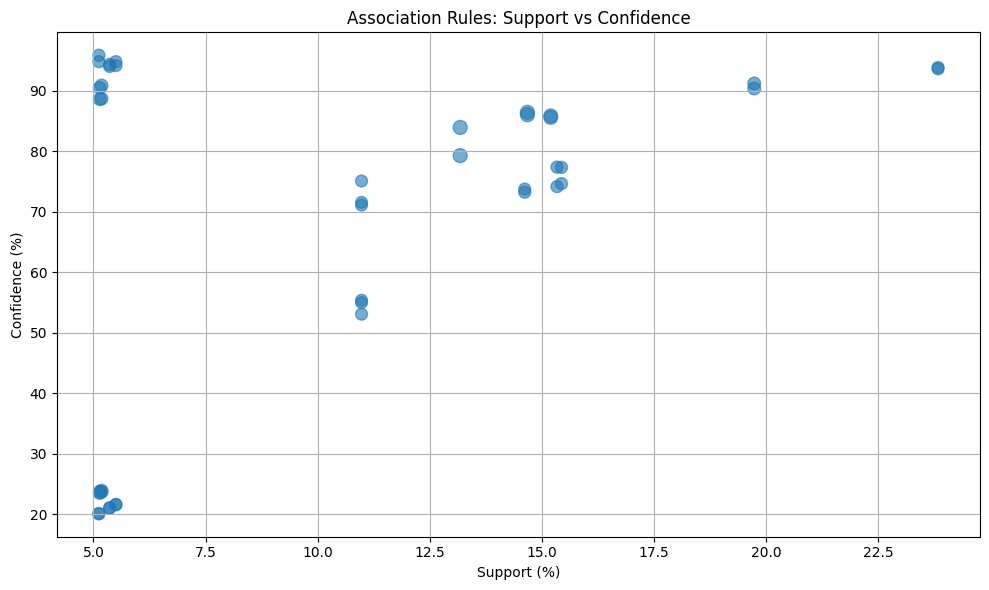

In [9]:
# Step 9: Association Rule Visualisation

if len(actionable_rules) > 0:

    plt.figure(figsize=(10, 6))

    plt.scatter(
        actionable_rules['Support'] * 100,
        actionable_rules['Confidence'] * 100,
        s=actionable_rules['Lift'] * 20,
        alpha=0.6
    )

    plt.xlabel("Support (%)")
    plt.ylabel("Confidence (%)")
    plt.title("Association Rules: Support vs Confidence")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("No rules satisfy the selected thresholds.")


In [10]:
# Step 10: Strongest Product Combinations

top_rules = rules.sort_values(
    by=['Lift', 'Support'],
    ascending=[False, False]
).head(10).copy()

top_rules['Support (%)'] = top_rules['Support'] * 100
top_rules['Confidence (%)'] = top_rules['Confidence'] * 100

print("Top 10 Association Rules:")

display(
    top_rules[
        ['Antecedents', 'Consequents',
         'Support (%)', 'Confidence (%)', 'Lift']
    ]
)


Top 10 Association Rules:


,Antecedents,Consequents,Support (%),Confidence (%),Lift
929,"Choco Cookies 150g, Face Wash 100ml","Hand Sanitizer 200ml, Instant Coffee 100g",2.06,75.182482,26.850886
932,"Hand Sanitizer 200ml, Instant Coffee 100g","Choco Cookies 150g, Face Wash 100ml",2.06,73.571429,26.850886
928,"Face Wash 100ml, Instant Coffee 100g","Choco Cookies 150g, Hand Sanitizer 200ml",2.06,74.100719,26.848087
933,"Choco Cookies 150g, Hand Sanitizer 200ml","Face Wash 100ml, Instant Coffee 100g",2.06,74.637681,26.848087
943,"Choco Cookies 150g, Poha 500g","Ghee 500ml, Instant Coffee 100g",2.34,77.483444,26.001156
946,"Ghee 500ml, Instant Coffee 100g","Choco Cookies 150g, Poha 500g",2.34,78.523490,26.001156
942,"Instant Coffee 100g, Poha 500g","Choco Cookies 150g, Ghee 500ml",2.34,78.000000,25.324675
947,"Choco Cookies 150g, Ghee 500ml","Instant Coffee 100g, Poha 500g",2.34,75.974026,25.324675
1082,"Poha 500g, White Bread 400g","Ghee 500ml, Toned Milk 1L",2.92,79.347826,21.798853
1087,"Ghee 500ml, Toned Milk 1L","Poha 500g, White Bread 400g",2.92,80.219780,21.798853


In [11]:

# Step 11: Business Recommendations

recommendations = []

for _, row in actionable_rules.iterrows():

    recommendations.append({
        'Product A': row['Antecedents'],
        'Product B': row['Consequents'],
        'Support (%)': round(row['Support'] * 100, 2),
        'Confidence (%)': round(row['Confidence'] * 100, 2),
        'Lift': round(row['Lift'], 2),
        'Recommendation':
            'Consider product bundling and cross-selling'
    })

recommendations_df = pd.DataFrame(recommendations)

print("BUSINESS RECOMMENDATIONS")

display(recommendations_df.head(15))


BUSINESS RECOMMENDATIONS


,Product A,Product B,Support (%),Confidence (%),Lift,Recommendation
0,Poha 500g,Ghee 500ml,14.68,86.45,5.07,Consider product bundling and cross-selling
1,Ghee 500ml,Poha 500g,14.68,86.05,5.07,Consider product bundling and cross-selling
2,Face Wash 100ml,Hand Sanitizer 200ml,13.18,83.95,5.05,Consider product bundling and cross-selling
3,Hand Sanitizer 200ml,Face Wash 100ml,13.18,79.30,5.05,Consider product bundling and cross-selling
4,Instant Coffee 100g,Choco Cookies 150g,15.20,85.88,4.84,Consider product bundling and cross-selling
5,Choco Cookies 150g,Instant Coffee 100g,15.20,85.59,4.84,Consider product bundling and cross-selling
6,Potato Chips 90g,Cola 750ml,19.74,90.38,4.18,Consider product bundling and cross-selling
7,Cola 750ml,Potato Chips 90g,19.74,91.22,4.18,Consider product bundling and cross-selling
8,"Cola 750ml, Toned Milk 1L",Potato Chips 90g,5.18,90.88,4.16,Consider product bundling and cross-selling
9,Potato Chips 90g,"Cola 750ml, Toned Milk 1L",5.18,23.72,4.16,Consider product bundling and cross-selling


In [12]:

# Step 12: Export Results

df_export = df.copy()

df_export['itemsets'] = df_export['itemsets'].apply(
    lambda x: ', '.join(sorted(x))
)

df_export.to_csv(
    'cleaned_frequent_itemsets.csv',
    index=False
)

rules.to_csv(
    'association_rules_generated.csv',
    index=False
)

recommendations_df.to_csv(
    'business_recommendations.csv',
    index=False
)

print("All result files saved successfully!")

from google.colab import files

files.download('association_rules_generated.csv')


All result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>